In [11]:

#######################################################################
# DESI D56 PAIRWISE kSZ PIPELINE
# Convention: Cluster 1 -> Cluster 2
#######################################################################

import numpy as np
import astropy.units as u
from astropy.cosmology import Planck18 as cosmo
from scipy.spatial import cKDTree


# =========================================================
# LOAD DATA
# =========================================================

redshift = np.load("redshift_desi_d56.npy")

coords = np.loadtxt(
    "desi_d56.dat",
    usecols=(0, 1)
)

temp = np.load(
    "kSZ_desi_d56_true_redshift_corrected.npy"
)

ra_deg = coords[:, 0]
dec_deg = coords[:, 1]


# =========================================================
# CHECKS
# =========================================================

if not (
    len(redshift) == len(ra_deg)
    == len(dec_deg) == len(temp)
):
    raise ValueError("Length mismatch")

if np.any(~np.isfinite(temp)):
    raise ValueError("Temperature array contains non-finite values")


# =========================================================
# COSMOLOGY DISTANCE
# =========================================================

D = cosmo.comoving_distance(redshift).to(u.Mpc).value

temp = temp - np.mean(temp)


# =========================================================
# CARTESIAN COORDINATES
# =========================================================

ra = np.deg2rad(ra_deg)
dec = np.deg2rad(dec_deg)

x = D * np.cos(dec) * np.cos(ra)
y = D * np.cos(dec) * np.sin(ra)
z_pos = D * np.sin(dec)

R = np.column_stack((x, y, z_pos))

R_norm = np.linalg.norm(R, axis=1)

if np.any(R_norm == 0):
    raise ValueError("An object has zero comoving distance")


# =========================================================
# INDIVIDUAL LINE-OF-SIGHT UNIT VECTORS
# =========================================================

rhat_los = R / R_norm[:, None]


# =========================================================
# PAIR SELECTION
# =========================================================

r_max = 50.0

tree = cKDTree(R)

pairs = tree.query_pairs(
    r=r_max,
    output_type="ndarray"
)


# =========================================================
# SEPARATION BINS
# =========================================================

bin_edges = np.array([
    1, 10, 20, 30, 40, 50
])

nbins = len(bin_edges) - 1

bin_centers = 0.5 * (
    bin_edges[:-1] + bin_edges[1:]
)

numerator = np.zeros(nbins)
denominator = np.zeros(nbins)

pair_counts = np.zeros(
    nbins,
    dtype=int
)


# =========================================================
# PAIRWISE kSZ ESTIMATOR
#
# Convention: Cluster 1 -> Cluster 2
#
# r_12 = R_2 - R_1
#
# rhat_12 = (R_2 - R_1) / |R_2 - R_1|
#
# c_12 = rhat_12 . [(rhat_1 + rhat_2)/2]
#
# Delta T_12 = T_1 - T_2
#
# p(r) = - Sum[(T_1 - T_2)c_12] / Sum[c_12^2]
# =========================================================

for i, j in pairs:

    # -----------------------------------------------------
    # Cluster 1 -> Cluster 2 separation vector
    # -----------------------------------------------------

    r_vec = R[j] - R[i]

    r_sep = np.linalg.norm(r_vec)

    if r_sep < 1e-10:
        continue


    # -----------------------------------------------------
    # Separation bin
    # -----------------------------------------------------

    bin_index = np.searchsorted(
        bin_edges,
        r_sep,
        side="right"
    ) - 1

    if bin_index < 0 or bin_index >= nbins:
        continue


    # -----------------------------------------------------
    # Unit separation vector: Cluster 1 -> Cluster 2
    # -----------------------------------------------------

    rhat_12 = r_vec / r_sep


    # -----------------------------------------------------
    # Individual line-of-sight unit vectors
    # -----------------------------------------------------

    rhat_1 = rhat_los[i]
    rhat_2 = rhat_los[j]


    # -----------------------------------------------------
    # Geometrical weighting factor
    #
    # c_12 = rhat_12 . [(rhat_1 + rhat_2)/2]
    # -----------------------------------------------------

    c12 = np.dot(
        rhat_12,
        0.5 * (rhat_1 + rhat_2)
    )


    # -----------------------------------------------------
    # Temperature difference
    #
    # Delta T_12 = T_1 - T_2
    # -----------------------------------------------------

    dT = temp[i] - temp[j]


    # -----------------------------------------------------
    # Accumulate numerator and denominator
    # -----------------------------------------------------

    numerator[bin_index] += dT * c12

    denominator[bin_index] += c12**2

    pair_counts[bin_index] += 1


# =========================================================
# FINAL PAIRWISE kSZ SIGNAL
# =========================================================

p_r = np.zeros(nbins)

mask = denominator > 0

p_r[mask] = (
    -numerator[mask] / denominator[mask]
)


# =========================================================
# PRINT RESULTS
# =========================================================

print("\n" + "=" * 75)
print("DESI D56 PAIRWISE kSZ RESULTS")
print("Convention: Cluster 1 -> Cluster 2")
print("=" * 75)

print(
    f"{'r_min':>10} "
    f"{'r_max':>10} "
    f"{'p(r)':>22} "
    f"{'pairs':>12}"
)

for b in range(nbins):

    print(
        f"{bin_edges[b]:10.2f} "
        f"{bin_edges[b+1]:10.2f} "
        f"{p_r[b]:22.10e} "
        f"{pair_counts[b]:12d}"
    )

print("=" * 75)

print(
    f"{'Total pairs:':>44} "
    f"{np.sum(pair_counts):>12d}"
)


# =========================================================
# SAVE NPZ
# =========================================================

np.savez(
    "desi_d56_kSZ_results.npz",
    bin_edges=bin_edges,
    bin_centers=bin_centers,
    p_r=p_r,
    pair_counts=pair_counts,
    numerator=numerator,
    denominator=denominator
)


# =========================================================
# SAVE TXT
# =========================================================

np.savetxt(
    "desi_d56_kSZ_results.txt",
    np.column_stack([
        bin_edges[:-1],
        bin_edges[1:],
        bin_centers,
        p_r,
        pair_counts
    ]),
    header="r_min r_max r_center p_r pair_counts"
)


# =========================================================
# SAVE NPY
# =========================================================

np.save("p_r.npy", p_r)
np.save("pair_counts.npy", pair_counts)
np.save("numerator.npy", numerator)
np.save("denominator.npy", denominator)
np.save("bin_centers.npy", bin_centers)


print("\nDONE - all results saved.")



DESI D56 PAIRWISE kSZ RESULTS
Convention: Cluster 1 -> Cluster 2
     r_min      r_max                   p(r)        pairs
      1.00      10.00      -1.2425730186e-07        11560
     10.00      20.00      -7.4882248495e-09        64998
     20.00      30.00       6.8917703882e-09       156491
     30.00      40.00       1.8644409338e-09       278805
     40.00      50.00       9.7783800662e-09       430821
                                Total pairs:       942675

DONE - all results saved.


Min z = 0.0322
Max z = 0.9778
Mean z = 0.4258
Median z = 0.4221


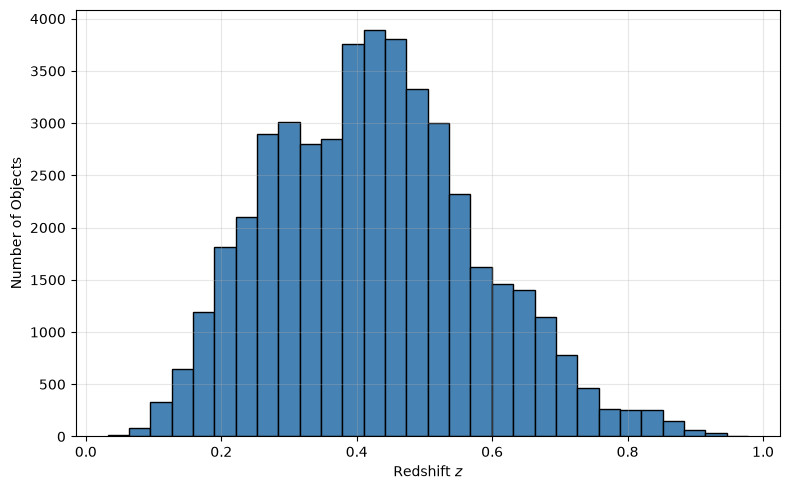

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(redshift, bins=30, color='steelblue', edgecolor='black')
plt.xlabel("Redshift $z$")
plt.ylabel("Number of Objects")
#plt.title("DESI D56 Redshift Distribution")
plt.grid(alpha=0.3)

print(f"Min z = {redshift.min():.4f}")
print(f"Max z = {redshift.max():.4f}")
print(f"Mean z = {redshift.mean():.4f}")
print(f"Median z = {np.median(redshift):.4f}")

plt.tight_layout()
plt.savefig(
    "DESI_D56_redshift_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Mean = -4.269353e-23 µK
Median = 3.099770e-08 µK
Std = 3.978114e-06 µK


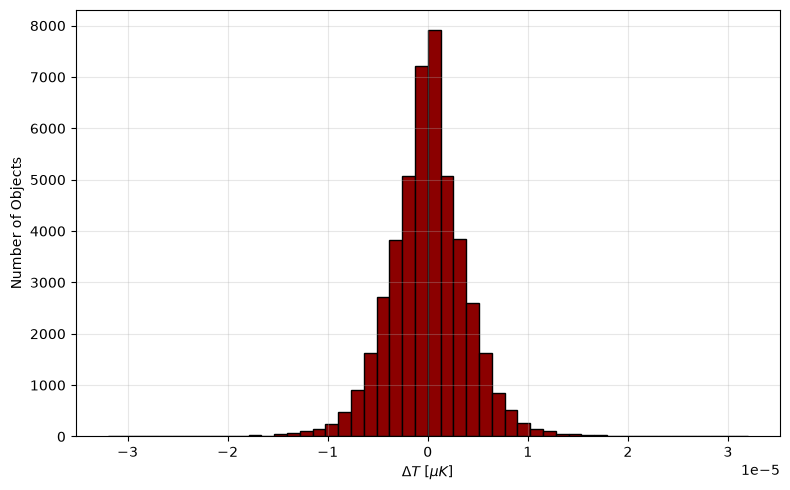

In [13]:
plt.figure(figsize=(8,5))
plt.hist(temp, bins=50, color='darkred', edgecolor='black')
plt.xlabel(r'$\Delta T\ [\mu K]$')
plt.ylabel("Number of Objects")
#plt.title("DESI D56 Aperture Photometry Temperature Distribution")
plt.grid(alpha=0.3)

print(f"Mean = {temp.mean():.6e} µK")
print(f"Median = {np.median(temp):.6e} µK")
print(f"Std = {temp.std():.6e} µK")

plt.tight_layout()
plt.savefig(
    "DESI_D56_temperature_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

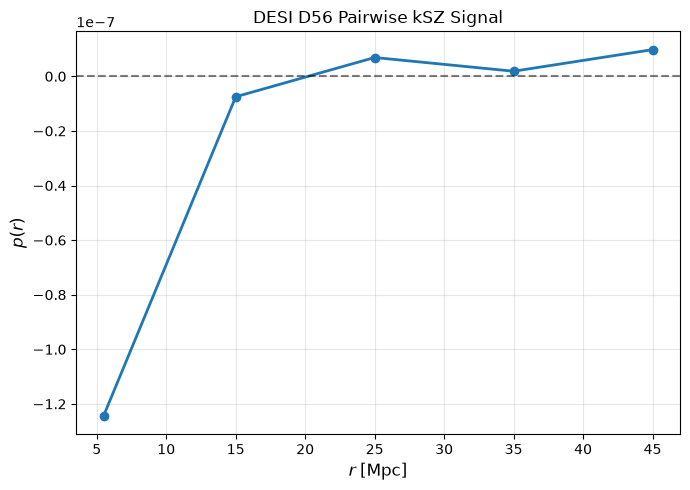

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# LOAD RESULTS
# =========================================================

data = np.load("desi_d56_kSZ_results.npz")

r = data["bin_centers"]
p_r = data["p_r"]

# =========================================================
# PLOT 1 : r vs p(r)
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    r,
    p_r,
    'o-',
    lw=2,
    ms=6
)

plt.axhline(0, color='k', ls='--', alpha=0.5)

plt.xlabel(r"$r\;[\mathrm{Mpc}]$", fontsize=12)
plt.ylabel(r"$p(r)$", fontsize=12)

plt.title("DESI D56 Pairwise kSZ Signal")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "pairwise_ksz_pr.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


DESI D56 PAIRWISE kSZ RESULTS
    Separation [Mpc]                  p(r)      Delta T [microK]   Number of pairs
------------------------------------------------------------------------------------------
          1.0 - 10.0      -1.2425730186e-07              -0.338601              11560
         10.0 - 20.0      -7.4882248495e-09              -0.020405              64998
         20.0 - 30.0       6.8917703882e-09               0.018780             156491
         30.0 - 40.0       1.8644409338e-09               0.005081             278805
         40.0 - 50.0       9.7783800662e-09               0.026646             430821


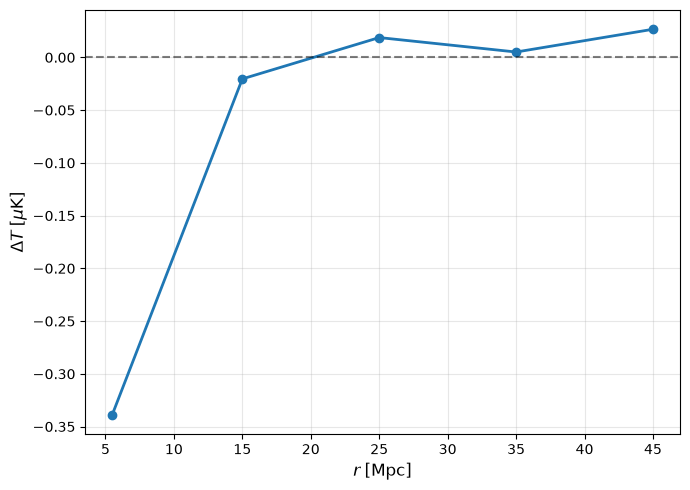


Converted results saved to pairwise_ksz_deltaT_results.txt


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# LOAD RESULTS
# =========================================================

data = np.load("desi_d56_kSZ_results.npz")

r = data["bin_centers"]
p_r = data["p_r"]
bin_edges = data["bin_edges"]
pair_counts = data["pair_counts"]

# =========================================================
# CONVERT DIMENSIONLESS p(r) TO TEMPERATURE IN MICROK
# =========================================================

T_CMB = 2.725  # K

delta_T = p_r * T_CMB * 1e6  # microK

# =========================================================
# DISPLAY RESULTS TABLE
# =========================================================

print("\nDESI D56 PAIRWISE kSZ RESULTS")
print("=" * 90)

print(
    f"{'Separation [Mpc]':>20}"
    f"{'p(r)':>22}"
    f"{'Delta T [microK]':>22}"
    f"{'Number of pairs':>18}"
)

print("-" * 90)

for i in range(len(r)):

    print(
        f"{bin_edges[i]:.1f} - {bin_edges[i+1]:.1f}".rjust(20),
        f"{p_r[i]:22.10e}",
        f"{delta_T[i]:22.6f}",
        f"{pair_counts[i]:18d}"
    )

print("=" * 90)

# =========================================================
# PLOT : r vs Delta T
# =========================================================

plt.figure(figsize=(7, 5))

plt.plot(
    r,
    delta_T,
    'o-',
    lw=2,
    ms=6
)

plt.axhline(0, color='k', ls='--', alpha=0.5)

plt.xlabel(r"$r\;[\mathrm{Mpc}]$", fontsize=12)
plt.ylabel(r"$\Delta T\;[\mu\mathrm{K}]$", fontsize=12)

#plt.title("DESI D56 Pairwise kSZ Signal")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "pairwise_ksz_deltaT.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================================================
# SAVE CONVERTED RESULTS TO TXT
# =========================================================

np.savetxt(
    "pairwise_ksz_deltaT_results.txt",
    np.column_stack([
        bin_edges[:-1],
        bin_edges[1:],
        r,
        p_r,
        delta_T,
        pair_counts
    ]),
    header="r_min_Mpc r_max_Mpc r_center_Mpc p_r delta_T_microK pair_counts",
    fmt=["%.2f", "%.2f", "%.2f", "%.10e", "%.6f", "%d"]
)

print("\nConverted results saved to pairwise_ksz_deltaT_results.txt")

In [4]:

#######################################################################
# DESI D56 kSZ — STEP 2 BOOTSTRAP COVARIANCE
# Convention: Cluster 1 (i) -> Cluster 2 (j)
#######################################################################

import numpy as np
from scipy.spatial import cKDTree
from astropy.cosmology import Planck18 as cosmo
import astropy.units as u

np.random.seed(42)

print("=" * 70)
print("BOOTSTRAP COVARIANCE (STEP 2)")
print("Convention: Cluster 1 -> Cluster 2")
print("=" * 70)


# =========================================================
# LOAD DATA
# =========================================================

coords = np.loadtxt(
    "desi_d56.dat",
    usecols=(0, 1)
)

redshift = np.load("redshift_desi_d56.npy")

temp = np.load(
    "kSZ_desi_d56_true_redshift_corrected.npy"
)

if not (
    len(coords) == len(redshift) == len(temp)
):
    raise ValueError("Length mismatch")

if np.any(~np.isfinite(temp)):
    raise ValueError("Temperature array contains non-finite values")

temp = temp - np.mean(temp)

ra = np.deg2rad(coords[:, 0])
dec = np.deg2rad(coords[:, 1])


# =========================================================
# COMOVING DISTANCES
# =========================================================

D = cosmo.comoving_distance(
    redshift
).to(u.Mpc).value


# =========================================================
# CARTESIAN COORDINATES
# =========================================================

R = np.column_stack([
    D * np.cos(dec) * np.cos(ra),
    D * np.cos(dec) * np.sin(ra),
    D * np.sin(dec)
])

N = len(R)

print(f"Loaded {N} clusters")


# =========================================================
# BINNING
# =========================================================

bin_edges = np.array([
    1, 10, 20, 30, 40, 50
])

nbins = len(bin_edges) - 1

r_centers = 0.5 * (
    bin_edges[:-1] + bin_edges[1:]
)

r_max = bin_edges[-1]


# =========================================================
# INDIVIDUAL LINE-OF-SIGHT UNIT VECTORS
# =========================================================

R_norm = np.linalg.norm(R, axis=1)

if np.any(R_norm == 0):
    raise ValueError("An object has zero comoving distance")

rhat_los = R / R_norm[:, None]


# =========================================================
# PAIR SELECTION
# =========================================================

print("Computing pairs...")

tree = cKDTree(R)

raw_pairs = tree.query_pairs(
    r=r_max,
    output_type="ndarray"
)


# =========================================================
# PRECOMPUTE VALID PAIRS
#
# Cluster 1 = i
# Cluster 2 = j
#
# r_12 = R[j] - R[i]
# =========================================================

valid_pairs = []
pair_bins = []

for i, j in raw_pairs:

    # Separation vector: Cluster 1 -> Cluster 2
    r_vec = R[j] - R[i]

    r_sep = np.linalg.norm(r_vec)

    if r_sep < 1e-10:
        continue

    # Separation bin
    bin_index = np.searchsorted(
        bin_edges,
        r_sep,
        side="right"
    ) - 1

    if bin_index < 0 or bin_index >= nbins:
        continue

    valid_pairs.append((i, j))
    pair_bins.append(bin_index)


pairs = np.asarray(
    valid_pairs,
    dtype=np.int64
)

pair_bins = np.asarray(
    pair_bins,
    dtype=np.int32
)

print(f"Total valid pairs: {len(pairs)}")


# =========================================================
# PRECOMPUTE GEOMETRICAL FACTORS
#
# c_12 = rhat_12 . [(rhat_1 + rhat_2)/2]
#
# rhat_12 = (R[j] - R[i]) / r_sep
# =========================================================

print("Computing geometrical factors...")

c12_all = np.zeros(len(pairs))

dT_all = np.zeros(len(pairs))

for k, (i, j) in enumerate(pairs):

    r_vec = R[j] - R[i]

    r_sep = np.linalg.norm(r_vec)

    rhat_12 = r_vec / r_sep

    rhat_1 = rhat_los[i]
    rhat_2 = rhat_los[j]

    c12_all[k] = np.dot(
        rhat_12,
        0.5 * (rhat_1 + rhat_2)
    )

    # Temperature difference: T_1 - T_2
    dT_all[k] = temp[i] - temp[j]


# =========================================================
# BASE ESTIMATOR FUNCTION
#
# p(r) = - Sum[w_ij (T_1 - T_2)c_12]
#        / Sum[w_ij c_12^2]
#
# w_ij = w_i * w_j
# =========================================================

def compute_pr(weights):

    num = np.zeros(nbins)
    den = np.zeros(nbins)

    for k, (i, j) in enumerate(pairs):

        # Bootstrap pair multiplicity
        w = weights[i] * weights[j]

        if w == 0:
            continue

        b = pair_bins[k]

        cij = c12_all[k]

        dT = dT_all[k]

        num[b] += w * dT * cij

        den[b] += w * cij**2

    p = np.zeros(nbins)

    ok = den > 0

    p[ok] = -num[ok] / den[ok]

    return p


# =========================================================
# FIDUCIAL p(r)
# =========================================================

print("Computing fiducial p(r)...")

p_fid = compute_pr(
    np.ones(N, dtype=np.int64)
)


# =========================================================
# VERIFY PAIR COUNTS
# =========================================================

pair_counts = np.bincount(
    pair_bins,
    minlength=nbins
)

print("\nPair counts:")
print("=" * 55)

for b in range(nbins):

    print(
        f"{bin_edges[b]:10.2f} "
        f"{bin_edges[b+1]:10.2f} "
        f"{pair_counts[b]:12d}"
    )

print("=" * 55)

print(
    f"{'Total valid pairs:':>25} "
    f"{pair_counts.sum():12d}"
)


# =========================================================
# BOOTSTRAP
# =========================================================

n_boot = 1000

boot = np.zeros(
    (n_boot, nbins)
)

print(
    f"\nStarting bootstrap: {n_boot} realizations"
)

for b in range(n_boot):

    print(
        f"Bootstrap {b + 1}/{n_boot}"
    )

    # Randomly resample N objects with replacement
    idx = np.random.randint(
        0,
        N,
        N
    )

    # Multiplicity of each object
    weights = np.bincount(
        idx,
        minlength=N
    )

    # Calculate pairwise signal
    boot[b] = compute_pr(weights)


# =========================================================
# BOOTSTRAP COVARIANCE MATRIX
# =========================================================

cov = np.cov(
    boot,
    rowvar=False
)

sigma = np.sqrt(
    np.diag(cov)
)

sigma[sigma == 0] = np.nan


# =========================================================
# CORRELATION MATRIX
# =========================================================

corr = cov / np.outer(sigma, sigma)


# =========================================================
# SAVE NPZ
# =========================================================

np.savez(
    "bootstrap_cluster_results.npz",

    bin_edges=bin_edges,

    r_centers=r_centers,

    p_fid=p_fid,

    bootstrap=boot,

    covariance=cov,

    correlation=corr,

    sigma=sigma,

    pair_counts=pair_counts,

    n_boot=n_boot
)


# =========================================================
# SAVE TXT
# =========================================================

np.savetxt(
    "bootstrap_cluster_results.txt",

    np.column_stack([
        r_centers,
        p_fid,
        sigma
    ]),

    header="r_center p_fid sigma",

    comments=""
)


# =========================================================
# PRINT RESULTS
# =========================================================

print("\n" + "=" * 70)
print("BOOTSTRAP RESULTS")
print("=" * 70)

print(
    f"{'r (Mpc)':>12} "
    f"{'p(r)':>20} "
    f"{'sigma':>20}"
)

for b in range(nbins):

    print(
        f"{r_centers[b]:12.2f} "
        f"{p_fid[b]:20.10e} "
        f"{sigma[b]:20.10e}"
    )

print("=" * 70)

print("\nBOOTSTRAP COMPLETE")

print("Saved:")
print("  bootstrap_cluster_results.npz")
print("  bootstrap_cluster_results.txt")


BOOTSTRAP COVARIANCE (STEP 2)
Convention: Cluster 1 -> Cluster 2
Loaded 45711 clusters
Computing pairs...
Total valid pairs: 942675
Computing geometrical factors...
Computing fiducial p(r)...

Pair counts:
      1.00      10.00        11560
     10.00      20.00        64998
     20.00      30.00       156491
     30.00      40.00       278805
     40.00      50.00       430821
       Total valid pairs:       942675

Starting bootstrap: 1000 realizations
Bootstrap 1/1000
Bootstrap 2/1000
Bootstrap 3/1000
Bootstrap 4/1000
Bootstrap 5/1000
Bootstrap 6/1000
Bootstrap 7/1000
Bootstrap 8/1000
Bootstrap 9/1000
Bootstrap 10/1000
Bootstrap 11/1000
Bootstrap 12/1000
Bootstrap 13/1000
Bootstrap 14/1000
Bootstrap 15/1000
Bootstrap 16/1000
Bootstrap 17/1000
Bootstrap 18/1000
Bootstrap 19/1000
Bootstrap 20/1000
Bootstrap 21/1000
Bootstrap 22/1000
Bootstrap 23/1000
Bootstrap 24/1000
Bootstrap 25/1000
Bootstrap 26/1000
Bootstrap 27/1000
Bootstrap 28/1000
Bootstrap 29/1000
Bootstrap 30/1000
Bootstrap 

In [5]:

#######################################################################
# DESI D56 kSZ — STEP 3 JACKKNIFE COVARIANCE
# Convention: Cluster 1 (i) -> Cluster 2 (j)
#######################################################################

import numpy as np
from scipy.spatial import cKDTree
from astropy.cosmology import Planck18 as cosmo
import astropy.units as u

np.random.seed(42)

print("=" * 70)
print("JACKKNIFE COVARIANCE (STEP 3)")
print("Convention: Cluster 1 -> Cluster 2")
print("=" * 70)


# =========================================================
# LOAD DATA
# =========================================================

coords = np.loadtxt(
    "desi_d56.dat",
    usecols=(0, 1)
)

redshift = np.load("redshift_desi_d56.npy")

temp = np.load(
    "kSZ_desi_d56_true_redshift_corrected.npy"
)

if not (
    len(coords) == len(redshift) == len(temp)
):
    raise ValueError("Length mismatch")

if np.any(~np.isfinite(temp)):
    raise ValueError("Temperature array contains non-finite values")

temp = temp - np.mean(temp)

ra = np.deg2rad(coords[:, 0])
dec = np.deg2rad(coords[:, 1])


# =========================================================
# COMOVING DISTANCES
# =========================================================

D = cosmo.comoving_distance(
    redshift
).to(u.Mpc).value


# =========================================================
# CARTESIAN COORDINATES
# =========================================================

R = np.column_stack([
    D * np.cos(dec) * np.cos(ra),
    D * np.cos(dec) * np.sin(ra),
    D * np.sin(dec)
])

N = len(R)

print(f"Loaded {N} clusters")


# =========================================================
# BINNING
# =========================================================

bin_edges = np.array([
    1, 10, 20, 30, 40, 50
])


nbins = len(bin_edges) - 1

r_centers = 0.5 * (
    bin_edges[:-1] + bin_edges[1:]
)

r_max = bin_edges[-1]


# =========================================================
# INDIVIDUAL LINE-OF-SIGHT UNIT VECTORS
# =========================================================

R_norm = np.linalg.norm(R, axis=1)

if np.any(R_norm == 0):
    raise ValueError("An object has zero comoving distance")

rhat_los = R / R_norm[:, None]


# =========================================================
# PAIR SELECTION
# =========================================================

print("Computing pairs...")

tree = cKDTree(R)

raw_pairs = tree.query_pairs(
    r=r_max,
    output_type="ndarray"
)


# =========================================================
# PRECOMPUTE VALID PAIRS
#
# Cluster 1 = i
# Cluster 2 = j
#
# r_12 = R[j] - R[i]
# =========================================================

valid_pairs = []
pair_bins = []

for i, j in raw_pairs:

    # Separation vector: Cluster 1 -> Cluster 2
    r_vec = R[j] - R[i]

    r_sep = np.linalg.norm(r_vec)

    if r_sep < 1e-10:
        continue

    # Separation bin
    bin_index = np.searchsorted(
        bin_edges,
        r_sep,
        side="right"
    ) - 1

    if bin_index < 0 or bin_index >= nbins:
        continue

    valid_pairs.append((i, j))
    pair_bins.append(bin_index)


pairs = np.asarray(
    valid_pairs,
    dtype=np.int64
)

pair_bins = np.asarray(
    pair_bins,
    dtype=np.int32
)

print(f"Total valid pairs: {len(pairs)}")


# =========================================================
# PRECOMPUTE GEOMETRICAL FACTORS
#
# c_12 = rhat_12 . [(rhat_1 + rhat_2)/2]
#
# rhat_12 = (R[j] - R[i]) / r_sep
# =========================================================

print("Computing geometrical factors...")

c12_all = np.zeros(len(pairs))

dT_all = np.zeros(len(pairs))

for k, (i, j) in enumerate(pairs):

    r_vec = R[j] - R[i]

    r_sep = np.linalg.norm(r_vec)

    rhat_12 = r_vec / r_sep

    rhat_1 = rhat_los[i]
    rhat_2 = rhat_los[j]

    c12_all[k] = np.dot(
        rhat_12,
        0.5 * (rhat_1 + rhat_2)
    )

    # Temperature difference: T_1 - T_2
    dT_all[k] = temp[i] - temp[j]


# =========================================================
# BASE ESTIMATOR FUNCTION
#
# p(r) = - Sum[w_ij (T_1 - T_2)c_12]
#        / Sum[w_ij c_12^2]
#
# w_ij = w_i * w_j
# =========================================================

def compute_pr(weights):

    num = np.zeros(nbins)
    den = np.zeros(nbins)

    for k, (i, j) in enumerate(pairs):

        # Jackknife pair weight
        w = weights[i] * weights[j]

        if w == 0:
            continue

        b = pair_bins[k]

        cij = c12_all[k]

        dT = dT_all[k]

        num[b] += w * dT * cij

        den[b] += w * cij**2

    p = np.zeros(nbins)

    ok = den > 0

    p[ok] = -num[ok] / den[ok]

    return p


# =========================================================
# FIDUCIAL p(r)
# =========================================================

print("Computing fiducial p(r)...")

p_fid = compute_pr(
    np.ones(N, dtype=np.int64)
)


# =========================================================
# VERIFY PAIR COUNTS
# =========================================================

pair_counts = np.bincount(
    pair_bins,
    minlength=nbins
)

print("\nPair counts:")
print("=" * 55)

for b in range(nbins):

    print(
        f"{bin_edges[b]:10.2f} "
        f"{bin_edges[b+1]:10.2f} "
        f"{pair_counts[b]:12d}"
    )

print("=" * 55)

print(
    f"{'Total valid pairs:':>25} "
    f"{pair_counts.sum():12d}"
)


# =========================================================
# JACKKNIFE
# =========================================================

n_jack = 50

jackknife = np.zeros(
    (n_jack, nbins)
)

regions = np.arange(N) % n_jack

print(
    f"\nStarting jackknife: {n_jack} realizations"
)

for b in range(n_jack):

    print(
        f"Jackknife {b + 1}/{n_jack}"
    )

    # Initially include all objects
    weights = np.ones(
        N,
        dtype=np.int64
    )

    # Remove one region
    weights[regions == b] = 0

    # Calculate pairwise signal
    jackknife[b] = compute_pr(weights)


# =========================================================
# JACKKNIFE MEAN
# =========================================================

jackknife_mean = np.mean(
    jackknife,
    axis=0
)


# =========================================================
# JACKKNIFE COVARIANCE MATRIX
# =========================================================

diff = jackknife - jackknife_mean

cov = (
    (n_jack - 1) / n_jack
) * (diff.T @ diff)


# =========================================================
# UNCERTAINTIES
# =========================================================

sigma = np.sqrt(
    np.diag(cov)
)

sigma[sigma == 0] = np.nan


# =========================================================
# CORRELATION MATRIX
# =========================================================

corr = cov / np.outer(sigma, sigma)


# =========================================================
# SAVE NPZ
# =========================================================

np.savez(
    "jackknife_cluster_results.npz",

    bin_edges=bin_edges,

    r_centers=r_centers,

    p_fid=p_fid,

    jackknife=jackknife,

    jackknife_mean=jackknife_mean,

    covariance=cov,

    correlation=corr,

    sigma=sigma,

    pair_counts=pair_counts,

    n_jack=n_jack
)


# =========================================================
# SAVE TXT
# =========================================================

np.savetxt(
    "jackknife_cluster_results.txt",

    np.column_stack([
        r_centers,
        p_fid,
        sigma
    ]),

    header="r_center p_fid sigma",

    comments=""
)


# =========================================================
# PRINT RESULTS
# =========================================================

print("\n" + "=" * 70)
print("JACKKNIFE RESULTS")
print("=" * 70)

print(
    f"{'r (Mpc)':>12} "
    f"{'p(r)':>20} "
    f"{'sigma':>20}"
)

for b in range(nbins):

    print(
        f"{r_centers[b]:12.2f} "
        f"{p_fid[b]:20.10e} "
        f"{sigma[b]:20.10e}"
    )

print("=" * 70)

print("\nJACKKNIFE COMPLETE")

print("Saved:")
print("  jackknife_cluster_results.npz")
print("  jackknife_cluster_results.txt")

print(f"Covariance matrix shape: {cov.shape}")


JACKKNIFE COVARIANCE (STEP 3)
Convention: Cluster 1 -> Cluster 2
Loaded 45711 clusters
Computing pairs...
Total valid pairs: 942675
Computing geometrical factors...
Computing fiducial p(r)...

Pair counts:
      1.00      10.00        11560
     10.00      20.00        64998
     20.00      30.00       156491
     30.00      40.00       278805
     40.00      50.00       430821
       Total valid pairs:       942675

Starting jackknife: 50 realizations
Jackknife 1/50
Jackknife 2/50
Jackknife 3/50
Jackknife 4/50
Jackknife 5/50
Jackknife 6/50
Jackknife 7/50
Jackknife 8/50
Jackknife 9/50
Jackknife 10/50
Jackknife 11/50
Jackknife 12/50
Jackknife 13/50
Jackknife 14/50
Jackknife 15/50
Jackknife 16/50
Jackknife 17/50
Jackknife 18/50
Jackknife 19/50
Jackknife 20/50
Jackknife 21/50
Jackknife 22/50
Jackknife 23/50
Jackknife 24/50
Jackknife 25/50
Jackknife 26/50
Jackknife 27/50
Jackknife 28/50
Jackknife 29/50
Jackknife 30/50
Jackknife 31/50
Jackknife 32/50
Jackknife 33/50
Jackknife 34/50
Jackknif

In [2]:
import numpy as np

# Load catalogue only
coords = np.loadtxt(
    "desi_d56.dat",
    usecols=(0,1)
)

N = len(coords)

# Load n_jack from saved file
data = np.load(
    "jackknife_cluster_results.npz"
)

n_jack = int(data["n_jack"])

# Recreate regions
regions = np.arange(N) % n_jack

# Count objects per region
region_counts = np.bincount(
    regions,
    minlength=n_jack
)

print("\nClusters per region")
print("="*40)

for r in range(n_jack):
    print(
        f"Region {r:2d}: "
        f"{region_counts[r]:5d} clusters"
    )

print("="*40)
print(f"Min  = {region_counts.min()}")
print(f"Max  = {region_counts.max()}")
print(f"Mean = {region_counts.mean():.2f}")


Clusters per region
Region  0:   915 clusters
Region  1:   915 clusters
Region  2:   915 clusters
Region  3:   915 clusters
Region  4:   915 clusters
Region  5:   915 clusters
Region  6:   915 clusters
Region  7:   915 clusters
Region  8:   915 clusters
Region  9:   915 clusters
Region 10:   915 clusters
Region 11:   914 clusters
Region 12:   914 clusters
Region 13:   914 clusters
Region 14:   914 clusters
Region 15:   914 clusters
Region 16:   914 clusters
Region 17:   914 clusters
Region 18:   914 clusters
Region 19:   914 clusters
Region 20:   914 clusters
Region 21:   914 clusters
Region 22:   914 clusters
Region 23:   914 clusters
Region 24:   914 clusters
Region 25:   914 clusters
Region 26:   914 clusters
Region 27:   914 clusters
Region 28:   914 clusters
Region 29:   914 clusters
Region 30:   914 clusters
Region 31:   914 clusters
Region 32:   914 clusters
Region 33:   914 clusters
Region 34:   914 clusters
Region 35:   914 clusters
Region 36:   914 clusters
Region 37:   914 

In [6]:

#######################################################################
# STEP 4 — THEORY p(r) FROM CAMB (POWER SPECTRUM AT z = 0)
#
# Pairwise velocity convention:
# Cluster 1 = i
# Cluster 2 = j
# r_12 = R_j - R_i
# v_12 = v_2 - v_1
#
# Negative v12 corresponds to infall.
#
# The linear matter power spectrum is calculated at z = 0.
# The correlation functions are evolved to z_eff using D(z)^2.
#######################################################################

import numpy as np
import camb
import astropy.units as u

from astropy.cosmology import FlatLambdaCDM
from scipy.interpolate import interp1d
from scipy.integrate import cumulative_trapezoid, quad

print("=" * 70)
print("STEP 4: THEORETICAL p(r) FROM CAMB")
print("=" * 70)


# =========================================================
# FIXED COSMOLOGY
# =========================================================

z_eff = 0.426
H0 = 67.4
Omega_m = 0.315

cosmo = FlatLambdaCDM(
    H0=H0,
    Om0=Omega_m
)

a = 1.0 / (1.0 + z_eff)

H_z = cosmo.H(z_eff).to(
    u.km / u.s / u.Mpc
).value

f = cosmo.Om(z_eff) ** 0.55

c_light = 3.0e5  # km/s

print(f"Effective redshift = {z_eff}")
print(f"H(z)              = {H_z:.6f} km/s/Mpc")
print(f"Growth rate f     = {f:.6f}")


# =========================================================
# LINEAR GROWTH FACTOR
#
# D(a) is normalised such that D(a=1) = 1.
#
# D(a) = [5 Omega_m E(a)/2]
#        * integral[0 to a] da' / [a'^3 E(a')^3]
#
# E(a) = H(a)/H0
# =========================================================

def growth_factor(a_value):

    def E_a(a_input):

        return np.sqrt(
            Omega_m / a_input**3
            + cosmo.Ode0
        )

    integral = quad(
        lambda ap: 1.0 / (
            ap**3 * E_a(ap)**3
        ),
        1e-8,
        a_value
    )[0]

    D = (
        5.0 * Omega_m / 2.0
        * E_a(a_value)
        * integral
    )

    return D


D0 = growth_factor(1.0)

D_eff = growth_factor(a) / D0

print(f"\nGrowth factor D(z) = {D_eff:.6f}")


# =========================================================
# LOAD SEPARATION BINS
# =========================================================

data = np.load("desi_d56_kSZ_results.npz")

r = np.asarray(
    data["bin_centers"],
    dtype=float
)

if len(r) < 4:
    raise ValueError(
        "At least four separation bins are required."
    )

if np.any(r <= 0) or not np.all(np.isfinite(r)):
    raise ValueError(
        "Invalid separation-bin centres."
    )

nbins = len(r)

print(f"\nLoaded {nbins} separation bins")


# =========================================================
# CAMB MATTER POWER SPECTRUM AT z = 0
# =========================================================

pars = camb.CAMBparams()

pars.set_cosmology(
    H0=H0,
    ombh2=0.022,
    omch2=0.12
)

pars.InitPower.set_params(
    As=2e-9,
    ns=0.965
)

pars.set_matter_power(
    redshifts=[0.0],
    kmax=10.0
)

pars.NonLinear = camb.model.NonLinear_none

results = camb.get_results(pars)

k_h, redshifts, pk = results.get_matter_power_spectrum(
    minkh=1e-4,
    maxkh=10.0,
    npoints=1200
)

pk = pk[0]

# Convert h/Mpc to 1/Mpc.
h = H0 / 100.0

k = k_h * h

# Convert power spectrum from (Mpc/h)^3 to Mpc^3.
pk = pk / h**3

if not (
    np.all(np.isfinite(k))
    and np.all(np.isfinite(pk))
):
    raise ValueError(
        "Invalid CAMB power-spectrum values."
    )


# =========================================================
# CALCULATE xi(r, z=0) ON A FINE RADIAL GRID
# =========================================================

r_min = 1e-3

r_max = float(np.max(r))

r_grid = np.logspace(
    np.log10(r_min),
    np.log10(r_max),
    1200
)

xi_grid_z0 = np.zeros_like(r_grid)

print("\nCalculating correlation function at z = 0...")

for i, ri in enumerate(r_grid):

    kr = k * ri

    sinc = np.sinc(kr / np.pi)

    xi_grid_z0[i] = (
        np.trapezoid(
            pk * k**2 * sinc,
            k
        )
        / (2.0 * np.pi**2)
    )


# =========================================================
# CALCULATE xi_bar(r, z=0)
#
# xi_bar(r) = 3/r^3 * integral[0 to r] xi(x) x^2 dx
#
# The integral is evaluated from r_min.
# =========================================================

integrand = xi_grid_z0 * r_grid**2

cumulative_integral = cumulative_trapezoid(
    integrand,
    r_grid,
    initial=0.0
)

xi_bar_grid_z0 = (
    3.0
    * cumulative_integral
    / r_grid**3
)


# =========================================================
# INTERPOLATE z=0 CORRELATION FUNCTIONS
# TO OBSERVED BIN CENTRES
# =========================================================

xi_interp = interp1d(
    r_grid,
    xi_grid_z0,
    kind="linear",
    bounds_error=True
)

xi_bar_interp = interp1d(
    r_grid,
    xi_bar_grid_z0,
    kind="linear",
    bounds_error=True
)

xi_z0 = np.asarray(
    xi_interp(r),
    dtype=float
)

xi_bar_z0 = np.asarray(
    xi_bar_interp(r),
    dtype=float
)


# =========================================================
# EVOLVE CORRELATION FUNCTIONS TO z_eff
#
# xi(r,z) = D(z)^2 * xi(r,0)
#
# xi_bar(r,z) = D(z)^2 * xi_bar(r,0)
# =========================================================

xi = D_eff**2 * xi_z0

xi_bar = D_eff**2 * xi_bar_z0


# =========================================================
# MEAN PAIRWISE VELOCITY v12(r, z_eff)
#
# v12(r) = -(2/3) f H a r xi_bar(r)/(1+xi(r))
# =========================================================

if np.any(np.isclose(1.0 + xi, 0.0)):
    raise ValueError(
        "Invalid denominator in pairwise velocity calculation."
    )

v12 = (
    -(2.0 / 3.0)
    * f
    * H_z
    * a
    * r
    * xi_bar
    / (1.0 + xi)
)


# =========================================================
# THEORETICAL PAIRWISE kSZ TEMPLATE p(r)
#
# Dimensionless temperature convention:
#
# p_theory(r) = -v12(r)/c
#
# Optical depth is fitted separately.
# =========================================================

p_theory = -v12 / c_light


# =========================================================
# CHECK RESULTS
# =========================================================

if not (
    np.all(np.isfinite(xi_z0))
    and np.all(np.isfinite(xi_bar_z0))
    and np.all(np.isfinite(xi))
    and np.all(np.isfinite(xi_bar))
    and np.all(np.isfinite(v12))
    and np.all(np.isfinite(p_theory))
):
    raise ValueError(
        "Non-finite values found in theoretical calculation."
    )


# =========================================================
# SAVE THEORETICAL RESULTS
# =========================================================

np.savez(
    "theory_pr_d56.npz",
    r=r,
    xi_z0=xi_z0,
    xi_bar_z0=xi_bar_z0,
    D_eff=D_eff,
    xi=xi,
    xi_bar=xi_bar,
    v12=v12,
    p_theory=p_theory
)


# =========================================================
# OUTPUT
# =========================================================

print("\n" + "=" * 70)
print("THEORETICAL PAIRWISE SIGNAL")
print("=" * 70)

print(f"Power spectrum redshift = 0")
print(f"Effective redshift      = {z_eff}")
print(f"Growth factor           = {D_eff:.6f}")

print("\n")

for i in range(nbins):

    print(
        f"{r[i]:6.2f} Mpc  "
        f"xi(z=0) = {xi_z0[i]:.6e}  "
        f"xi(z_eff) = {xi[i]:.6e}  "
        f"xi_bar(z_eff) = {xi_bar[i]:.6e}  "
        f"v12 = {v12[i]:.6e} km/s  "
        f"p_theory = {p_theory[i]:.6e}"
    )

print("=" * 70)

print("\nSaved: theory_pr_d56.npz")

print(
    "\nSTEP 4 COMPLETE — "
    "THEORETICAL PAIRWISE SIGNAL READY."
)


STEP 4: THEORETICAL p(r) FROM CAMB
Effective redshift = 0.426
H(z)              = 85.212823 km/s/Mpc
Growth rate f     = 0.735087

Growth factor D(z) = 0.798588

Loaded 5 separation bins

Calculating correlation function at z = 0...

THEORETICAL PAIRWISE SIGNAL
Power spectrum redshift = 0
Effective redshift      = 0.426
Growth factor           = 0.798588


  5.50 Mpc  xi(z=0) = 1.364536e+00  xi(z_eff) = 8.702222e-01  xi_bar(z_eff) = 1.356595e+00  v12 = -1.168294e+02 km/s  p_theory = 3.894314e-04
 15.00 Mpc  xi(z=0) = 3.255788e-01  xi(z_eff) = 2.076354e-01  xi_bar(z_eff) = 3.945628e-01  v12 = -1.435173e+02 km/s  p_theory = 4.783909e-04
 25.00 Mpc  xi(z=0) = 1.267399e-01  xi(z_eff) = 8.082739e-02  xi_bar(z_eff) = 1.803769e-01  v12 = -1.221792e+02 km/s  p_theory = 4.072641e-04
 35.00 Mpc  xi(z=0) = 6.106538e-02  xi(z_eff) = 3.894398e-02  xi_bar(z_eff) = 1.003068e-01  v12 = -9.895530e+01 km/s  p_theory = 3.298510e-04
 45.00 Mpc  xi(z=0) = 3.286479e-02  xi(z_eff) = 2.095927e-02  xi_bar(z_ef

In [6]:
#######################################################################
# THEORETICAL PAIRWISE kSZ SIGNAL IN MICROK
#
# Converts:
#     p_theory(r)
#
# to
#
#     Delta T = p_theory * Tcmb
#
#######################################################################

import numpy as np

# =========================================================
# LOAD THEORY RESULTS
# =========================================================

data = np.load("theory_pr_d56.npz")

r = data["r"]
p_theory = data["p_theory"]
v12 = data["v12"]

# =========================================================
# CONVERT TO MICROK
# =========================================================

T_CMB = 2.725  # K

delta_T = p_theory * T_CMB * 1e6

# =========================================================
# DISPLAY RESULTS
# =========================================================

print("\nTHEORETICAL PAIRWISE kSZ SIGNAL")
print("=" * 100)

print(
    f"{'r [Mpc]':>12}"
    f"{'v12 [km/s]':>22}"
    f"{'p_theory':>22}"
    f"{'Delta T [microK]':>22}"
)

print("-" * 100)

for i in range(len(r)):

    print(
        f"{r[i]:12.2f}"
        f"{v12[i]:22.10e}"
        f"{p_theory[i]:22.10e}"
        f"{delta_T[i]:22.6f}"
    )

print("=" * 100)

# =========================================================
# SAVE RESULTS
# =========================================================

np.savetxt(
    "theoretical_pairwise_ksz_deltaT.txt",
    np.column_stack([
        r,
        v12,
        p_theory,
        delta_T
    ]),
    header="r_Mpc v12_km_s p_theory delta_T_microK",
    fmt=[
        "%.4f",
        "%.10e",
        "%.10e",
        "%.10f"
    ]
)

print(
    "\nConverted results saved to "
    "theoretical_pairwise_ksz_deltaT.txt"
)


THEORETICAL PAIRWISE kSZ SIGNAL
     r [Mpc]            v12 [km/s]              p_theory      Delta T [microK]
----------------------------------------------------------------------------------------------------
        5.50     -1.1682941548e+02      3.8943138494e-04           1061.200524
       15.00     -1.4351726862e+02      4.7839089542e-04           1303.615190
       25.00     -1.2217921558e+02      4.0726405194e-04           1109.794542
       35.00     -9.8955298483e+01      3.2985099494e-04            898.843961
       45.00     -8.0097175571e+01      2.6699058524e-04            727.549345

Converted results saved to theoretical_pairwise_ksz_deltaT.txt


In [7]:

import numpy as np

# =========================================================
# PAIRWISE kSZ SIGNAL IN MICROK
# DESI D56: FIVE SEPARATION BINS
# =========================================================

# Separation bin centres (Mpc)
r = np.array([5.0, 15.0, 25.0, 35.0, 45.0])

# Separation bin limits
r_min = np.array([1, 10, 20, 30, 40])
r_max = np.array([10, 20, 30, 40, 50])

# Number of galaxy pairs
pairs = np.array([
    11560,
    64998,
    156491,
    278805,
    430821
])

# =========================================================
# MEASURED PAIRWISE kSZ SIGNAL
# =========================================================

p_measured = np.array([
   -1.2425730186e-07,
   -7.4882248495e-09,
    6.8917703882e-09,
    1.8644409338e-09,
    9.7783800662e-09
])

# =========================================================
# THEORETICAL CAMB PAIRWISE SIGNAL
# =========================================================

p_theory = np.array([
    3.8943138494e-04,
    4.7839089542e-04,
    4.0726405194e-04,
    3.2985099494e-04,
    2.6699058524e-04
])

# =========================================================
# CONVERT TO MICROK
# =========================================================

T_CMB = 2.725  # K

deltaT_measured = p_measured * T_CMB * 1e6
deltaT_theory = p_theory * T_CMB * 1e6

# =========================================================
# DISPLAY RESULTS
# =========================================================

print("\nDESI D56 PAIRWISE kSZ SIGNAL IN MICROK")
print("=" * 125)

print(
    f"{'r_min':>8}"
    f"{'r_max':>8}"
    f"{'r_centre':>12}"
    f"{'Pairs':>12}"
    f"{'p_measured':>18}"
    f"{'p_theory':>18}"
    f"{'Measured [microK]':>22}"
    f"{'Theory [microK]':>20}"
)

print("-" * 125)

for i in range(len(r)):

    print(
        f"{r_min[i]:8.1f}"
        f"{r_max[i]:8.1f}"
        f"{r[i]:12.1f}"
        f"{pairs[i]:12d}"
        f"{p_measured[i]:18.10e}"
        f"{p_theory[i]:18.10e}"
        f"{deltaT_measured[i]:22.6f}"
        f"{deltaT_theory[i]:20.6f}"
    )

print("=" * 125)

print(f"Total pairs: {np.sum(pairs)}")

# =========================================================
# SAVE RESULTS
# =========================================================

np.savetxt(
    "pairwise_ksz_microK_comparison_5bins.txt",
    np.column_stack([
        r_min,
        r_max,
        r,
        pairs,
        p_measured,
        p_theory,
        deltaT_measured,
        deltaT_theory
    ]),
    header=(
        "r_min_Mpc r_max_Mpc r_centre_Mpc pairs "
        "p_measured p_theory "
        "measured_microK theory_microK"
    ),
    fmt="%.10e"
)

print("\nSaved: pairwise_ksz_microK_comparison_5bins.txt")



DESI D56 PAIRWISE kSZ SIGNAL IN MICROK
   r_min   r_max    r_centre       Pairs        p_measured          p_theory     Measured [microK]     Theory [microK]
-----------------------------------------------------------------------------------------------------------------------------
     1.0    10.0         5.0       11560 -1.2425730186e-07  3.8943138494e-04             -0.338601         1061.200524
    10.0    20.0        15.0       64998 -7.4882248495e-09  4.7839089542e-04             -0.020405         1303.615190
    20.0    30.0        25.0      156491  6.8917703882e-09  4.0726405194e-04              0.018780         1109.794542
    30.0    40.0        35.0      278805  1.8644409338e-09  3.2985099494e-04              0.005081          898.843961
    40.0    50.0        45.0      430821  9.7783800662e-09  2.6699058524e-04              0.026646          727.549345
Total pairs: 942675

Saved: pairwise_ksz_microK_comparison_5bins.txt



Figure saved as: pairwise_kSZ_microK_measurement_vs_theory_5bins.png


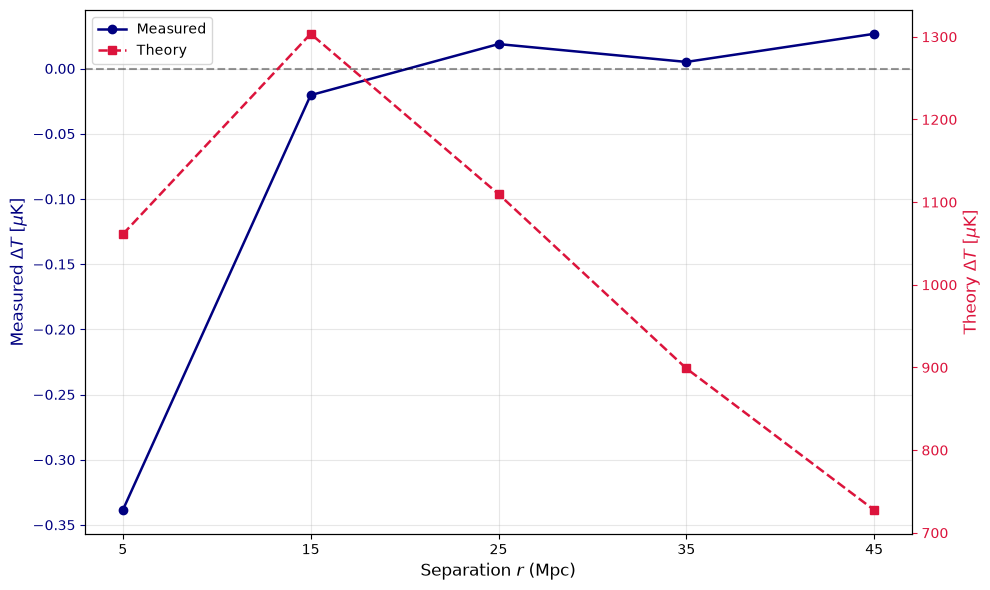

In [8]:

import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# DATA: DESI D56 — FIVE SEPARATION BINS
# =========================================================

r = np.array([
    5.0, 15.0, 25.0, 35.0, 45.0
])

# Measured pairwise kSZ signal
p_measured = np.array([
   -1.2425730186e-07,
   -7.4882248495e-09,
    6.8917703882e-09,
    1.8644409338e-09,
    9.7783800662e-09
])

# CAMB theoretical pairwise kSZ signal
p_theory = np.array([
    3.8943138494e-04,
    4.7839089542e-04,
    4.0726405194e-04,
    3.2985099494e-04,
    2.6699058524e-04
])

# =========================================================
# CONVERT TO MICROK
# =========================================================

T_CMB = 2.725

deltaT_measured = p_measured * T_CMB * 1e6
deltaT_theory = p_theory * T_CMB * 1e6

# =========================================================
# PLOT
# =========================================================

fig, ax1 = plt.subplots(figsize=(10, 6))

# Measured signal
ax1.plot(
    r,
    deltaT_measured,
    marker='o',
    linestyle='-',
    linewidth=1.8,
    markersize=6,
    color='navy',
    label='Measured'
)

ax1.set_xlabel(
    r'Separation $r$ (Mpc)',
    fontsize=12
)

ax1.set_ylabel(
    r'Measured $\Delta T$ [$\mu$K]',
    color='navy',
    fontsize=12
)

ax1.tick_params(
    axis='y',
    colors='navy'
)

ax1.axhline(
    0,
    color='k',
    ls='--',
    alpha=0.4
)

ax1.set_xticks(r)
ax1.grid(alpha=0.3)

# Theory signal
ax2 = ax1.twinx()

ax2.plot(
    r,
    deltaT_theory,
    marker='s',
    linestyle='--',
    linewidth=1.8,
    markersize=6,
    color='crimson',
    label='Theory'
)

ax2.set_ylabel(
    r'Theory $\Delta T$ [$\mu$K]',
    color='crimson',
    fontsize=12
)

ax2.tick_params(
    axis='y',
    colors='crimson'
)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc='best'
)

plt.tight_layout()

# =========================================================
# SAVE FIGURE
# =========================================================

plt.savefig(
    "pairwise_kSZ_microK_measurement_vs_theory_5bins.png",
    dpi=600,
    bbox_inches="tight"
)

print(
    "\nFigure saved as: "
    "pairwise_kSZ_microK_measurement_vs_theory_5bins.png"
)

plt.show()


In [7]:

#######################################################################
# STEP 5 — TAU FIT (JACKKNIFE VERSION)
#
# Pair convention:
# Cluster 1 = i
# Cluster 2 = j
# r_12 = R_j - R_i
# Delta T_12 = T_i - T_j
# c_12 = rhat_12 . (rhat_i + rhat_j)/2
# p_kSZ(r) = -sum[(T_i - T_j)c_12] / sum[c_12^2]
#
# Theoretical signal:
# Loaded from theory_pr_d56.npz, calculated using P(k, z=0)
# and evolved to z_eff using the linear growth factor.
#######################################################################

import numpy as np
import emcee

print("=" * 70)
print("STEP 5: TAU FIT (JACKKNIFE)")
print("=" * 70)


# =========================================================
# LOAD OBSERVED PAIRWISE SIGNAL
# =========================================================

obs = np.load("desi_d56_kSZ_results.npz")

r = np.asarray(obs["bin_centers"], dtype=float)
p_obs = np.asarray(obs["p_r"], dtype=float)


# =========================================================
# LOAD THEORETICAL PAIRWISE SIGNAL
# =========================================================

# Step 4 calculates P(k) at z = 0 and evolves the
# correlation function to z_eff using D(z_eff)^2.

th = np.load("theory_pr_d56.npz")

p_th = np.asarray(th["p_theory"], dtype=float)

nbins = len(r)

if len(p_obs) != nbins:
    raise ValueError("Mismatch between observed signal and separation bins")

if len(p_th) != nbins:
    raise ValueError("Mismatch between theoretical signal and separation bins")

if not (
    np.all(np.isfinite(r))
    and np.all(np.isfinite(p_obs))
    and np.all(np.isfinite(p_th))
):
    raise ValueError("Non-finite values found in observed or theoretical signal")


# =========================================================
# LOAD JACKKNIFE COVARIANCE
# =========================================================

cov_data = np.load("jackknife_cluster_results.npz")

cov = np.asarray(cov_data["covariance"], dtype=float)

if cov.shape != (nbins, nbins):
    raise ValueError("Jackknife covariance matrix has incorrect dimensions")

if not np.all(np.isfinite(cov)):
    raise ValueError("Non-finite values found in jackknife covariance matrix")


# =========================================================
# SYMMETRISE + STABILISE COVARIANCE
# =========================================================

cov = 0.5 * (cov + cov.T)

cov += 1e-10 * np.eye(nbins)

cov_inv = np.linalg.pinv(cov)


# =========================================================
# MODEL
# =========================================================

def model(tau):
    return tau * p_th


# =========================================================
# CHI-SQUARE
# =========================================================

def chi2(tau):

    diff = p_obs - model(tau)

    return float(diff @ cov_inv @ diff)


# =========================================================
# ANALYTIC BEST-FIT TAU
# =========================================================

A = p_th

denom = float(A @ cov_inv @ A)

if not np.isfinite(denom) or denom <= 0:
    raise ValueError("Non-positive or invalid denominator in tau fit")

tau_unconstrained = float(
    (A @ cov_inv @ p_obs) / denom
)


# =========================================================
# APPLYING PHYSICAL PRIOR
# =========================================================

tau_min = 0.006
tau_max = 0.04

tau_best = float(
    np.clip(tau_unconstrained, tau_min, tau_max)
)


# =========================================================
# BEST-FIT CHI-SQUARE
# =========================================================

chi2_best = chi2(tau_best)

chi2_red = chi2_best / (nbins - 1)


# =========================================================
# MCMC LOG-PROBABILITY
# =========================================================

def log_prob(theta):

    tau = theta[0]

    if tau < tau_min or tau > tau_max:
        return -np.inf

    return -0.5 * chi2(tau)


# =========================================================
# MCMC INITIAL CONDITIONS
# =========================================================

nwalkers = 32
ndim = 1

np.random.seed(42)

p0 = np.zeros((nwalkers, ndim))

if tau_best > 0.0:

    p0[:, 0] = (
        tau_best
        + 0.1 * tau_best * np.random.randn(nwalkers)
    )

else:

    p0[:, 0] = (
        1e-6 * np.abs(np.random.randn(nwalkers))
    )

p0[:, 0] = np.clip(
    p0[:, 0],
    1e-12,
    tau_max - 1e-12
)


# =========================================================
# RUN MCMC
# =========================================================

sampler = emcee.EnsembleSampler(
    nwalkers,
    ndim,
    log_prob
)

print("\nRunning MCMC...")

sampler.run_mcmc(
    p0,
    2000,
    progress=True
)


# =========================================================
# EXTRACT POSTERIOR
# =========================================================

samples = sampler.get_chain(
    discard=500,
    flat=True
)[:, 0]

if len(samples) == 0:
    raise ValueError("No MCMC samples were produced")

tau_mcmc = float(np.percentile(samples, 50))

tau_lo, tau_hi = np.percentile(samples, [16, 84])


# =========================================================
# UNCERTAINTIES
# =========================================================

tau_plus = float(tau_hi - tau_mcmc)

tau_minus = float(tau_mcmc - tau_lo)

tau_sym = 0.5 * (tau_plus + tau_minus)

tau_err = tau_sym


# =========================================================
# OUTPUT
# =========================================================

print("\n" + "=" * 70)
print("JACKKNIFE TAU FIT RESULTS")
print("=" * 70)

print(f"tau unconstrained = {tau_unconstrained:.16e}")
print(f"tau best-fit      = {tau_best:.16e}")

print(
    f"tau MCMC          = {tau_mcmc:.16e} "
    f"+{tau_plus:.16e} -{tau_minus:.16e}"
)

print(
    f"tau (sym)         = {tau_mcmc:.16e} "
    f"+/- {tau_sym:.16e}"
)

print(
    f"chi2              = {chi2_best:.16e} "
    f"(rounded: {chi2_best:.3f})"
)

print(
    f"chi2 reduced      = {chi2_red:.16e} "
    f"(rounded: {chi2_red:.3f})"
)

print("=" * 70)


# =========================================================
# SAVE RESULTS
# =========================================================

np.savez(
    "tau_fit_results_jackknife.npz",
    r=r,
    p_obs=p_obs,
    p_theory=p_th,
    tau_unconstrained=tau_unconstrained,
    tau_best=tau_best,
    tau_mcmc=tau_mcmc,
    tau_err=tau_err,
    tau_sym=tau_sym,
    tau_low=tau_lo,
    tau_high=tau_hi,
    chi2=chi2_best,
    chi2_red=chi2_red,
    cov=cov,
    samples=samples
)

print("\nSTEP 5 COMPLETE — JACKKNIFE TAU FIT SAVED.")


You must install the tqdm library to use progress indicators with emcee


STEP 5: TAU FIT (JACKKNIFE)

Running MCMC...

JACKKNIFE TAU FIT RESULTS
tau unconstrained = -6.3227755215940548e-05
tau best-fit      = 0.0000000000000000e+00
tau MCMC          = 4.5360483750496276e-03 +3.5116120873654195e-03 -3.0770573267591616e-03
tau (sym)         = 4.5360483750496276e-03 +/- 3.2943347070622906e-03
chi2              = 1.5639232841487376e-04 (rounded: 0.000)
chi2 reduced      = 3.9098082103718441e-05 (rounded: 0.000)

STEP 5 COMPLETE — JACKKNIFE TAU FIT SAVED.


In [8]:

#######################################################################
# STEP 6 — TAU FIT (BOOTSTRAP VERSION)
#
# Pair convention:
# Cluster 1 = i
# Cluster 2 = j
# r_12 = R_j - R_i
# Delta T_12 = T_i - T_j
# c_12 = rhat_12 . (rhat_i + rhat_j)/2
# p_kSZ(r) = -sum[(T_i - T_j)c_12] / sum[c_12^2]
#
# Theoretical signal:
# Loaded from theory_pr_d56.npz, calculated using P(k, z=0)
# and evolved to z_eff using the linear growth factor.
#######################################################################

import numpy as np
import emcee

print("=" * 70)
print("STEP 6: TAU FIT (BOOTSTRAP)")
print("=" * 70)


# =========================================================
# LOAD OBSERVED PAIRWISE SIGNAL
# =========================================================

obs = np.load("desi_d56_kSZ_results.npz")

r = np.asarray(obs["bin_centers"], dtype=float)
p_obs = np.asarray(obs["p_r"], dtype=float)


# =========================================================
# LOAD THEORETICAL PAIRWISE SIGNAL
# =========================================================

# This file must be generated by the updated Step 4.
# Step 4 calculates P(k) at z = 0 and evolves the
# correlation function to z_eff using D(z_eff)^2.

th = np.load("theory_pr_d56.npz")

p_th = np.asarray(th["p_theory"], dtype=float)

nbins = len(r)

if len(p_obs) != nbins:
    raise ValueError("Mismatch between observed signal and separation bins")

if len(p_th) != nbins:
    raise ValueError("Mismatch between theoretical signal and separation bins")

if not (
    np.all(np.isfinite(r))
    and np.all(np.isfinite(p_obs))
    and np.all(np.isfinite(p_th))
):
    raise ValueError("Non-finite values found in observed or theoretical signal")


# =========================================================
# LOAD BOOTSTRAP COVARIANCE
# =========================================================

cov_data = np.load("bootstrap_cluster_results.npz")

cov = np.asarray(cov_data["covariance"], dtype=float)

if cov.shape != (nbins, nbins):
    raise ValueError("Bootstrap covariance matrix has incorrect dimensions")

if not np.all(np.isfinite(cov)):
    raise ValueError("Non-finite values found in bootstrap covariance matrix")


# =========================================================
# SYMMETRISE + STABILISE COVARIANCE
# =========================================================

cov = 0.5 * (cov + cov.T)

cov += 1e-10 * np.eye(nbins)

cov_inv = np.linalg.pinv(cov)


# =========================================================
# MODEL
# =========================================================

def model(tau):
    return tau * p_th


# =========================================================
# CHI-SQUARE
# =========================================================

def chi2(tau):

    diff = p_obs - model(tau)

    return float(diff @ cov_inv @ diff)


# =========================================================
# ANALYTIC BEST-FIT TAU
# =========================================================

A = p_th

denom = float(A @ cov_inv @ A)

if not np.isfinite(denom) or denom <= 0:
    raise ValueError("Non-positive or invalid denominator in tau fit")

tau_unconstrained = float(
    (A @ cov_inv @ p_obs) / denom
)


# =========================================================
# APPLY PHYSICAL PRIOR
# =========================================================

tau_min = 0.006
tau_max = 0.04

tau_best = float(
    np.clip(tau_unconstrained, tau_min, tau_max)
)


# =========================================================
# BEST-FIT CHI-SQUARE
# =========================================================

chi2_best = chi2(tau_best)

chi2_red = chi2_best / (nbins - 1)


# =========================================================
# MCMC LOG-PROBABILITY
# =========================================================

def log_prob(theta):

    tau = theta[0]

    if tau < tau_min or tau > tau_max:
        return -np.inf

    return -0.5 * chi2(tau)


# =========================================================
# MCMC INITIAL CONDITIONS
# =========================================================

nwalkers = 32
ndim = 1

np.random.seed(42)

p0 = np.zeros((nwalkers, ndim))

if tau_best > 0.0:

    p0[:, 0] = (
        tau_best
        + 0.1 * tau_best * np.random.randn(nwalkers)
    )

else:

    p0[:, 0] = (
        1e-6 * np.abs(np.random.randn(nwalkers))
    )

p0[:, 0] = np.clip(
    p0[:, 0],
    1e-12,
    tau_max - 1e-12
)


# =========================================================
# RUN MCMC
# =========================================================

sampler = emcee.EnsembleSampler(
    nwalkers,
    ndim,
    log_prob
)

print("\nRunning MCMC...")

sampler.run_mcmc(
    p0,
    2000,
    progress=True
)


# =========================================================
# EXTRACT POSTERIOR
# =========================================================

samples = sampler.get_chain(
    discard=500,
    flat=True
)[:, 0]

if len(samples) == 0:
    raise ValueError("No MCMC samples were produced")

tau_mcmc = float(np.percentile(samples, 50))

tau_lo, tau_hi = np.percentile(samples, [16, 84])


# =========================================================
# UNCERTAINTIES
# =========================================================

tau_plus = float(tau_hi - tau_mcmc)

tau_minus = float(tau_mcmc - tau_lo)

tau_sym = 0.5 * (tau_plus + tau_minus)

tau_err = tau_sym


# =========================================================
# OUTPUT
# =========================================================

print("\n" + "=" * 70)
print("BOOTSTRAP TAU FIT RESULTS")
print("=" * 70)

print(f"tau unconstrained = {tau_unconstrained:.16e}")
print(f"tau best-fit      = {tau_best:.16e}")

print(
    f"tau MCMC          = {tau_mcmc:.16e} "
    f"+{tau_plus:.16e} -{tau_minus:.16e}"
)

print(
    f"tau (sym)         = {tau_mcmc:.16e} "
    f"+/- {tau_sym:.16e}"
)

print(
    f"chi2              = {chi2_best:.16e} "
    f"(rounded: {chi2_best:.3f})"
)

print(
    f"chi2 reduced      = {chi2_red:.16e} "
    f"(rounded: {chi2_red:.3f})"
)

print("=" * 70)


# =========================================================
# SAVE RESULTS
# =========================================================

np.savez(
    "tau_fit_results_bootstrap.npz",
    r=r,
    p_obs=p_obs,
    p_theory=p_th,
    tau_unconstrained=tau_unconstrained,
    tau_best=tau_best,
    tau_mcmc=tau_mcmc,
    tau_err=tau_err,
    tau_sym=tau_sym,
    tau_low=tau_lo,
    tau_high=tau_hi,
    chi2=chi2_best,
    chi2_red=chi2_red,
    cov=cov,
    samples=samples
)

print("\nSTEP 6 COMPLETE — BOOTSTRAP TAU FIT SAVED.")


You must install the tqdm library to use progress indicators with emcee


STEP 6: TAU FIT (BOOTSTRAP)

Running MCMC...

BOOTSTRAP TAU FIT RESULTS
tau unconstrained = -6.3225934115080783e-05
tau best-fit      = 0.0000000000000000e+00
tau MCMC          = 4.5360483750496276e-03 +3.5116120873654195e-03 -3.0770573267591616e-03
tau (sym)         = 4.5360483750496276e-03 +/- 3.2943347070622906e-03
chi2              = 1.5638972155136081e-04 (rounded: 0.000)
chi2 reduced      = 3.9097430387840203e-05 (rounded: 0.000)

STEP 6 COMPLETE — BOOTSTRAP TAU FIT SAVED.


STEP 7: TAU POSTERIOR COMPARISON


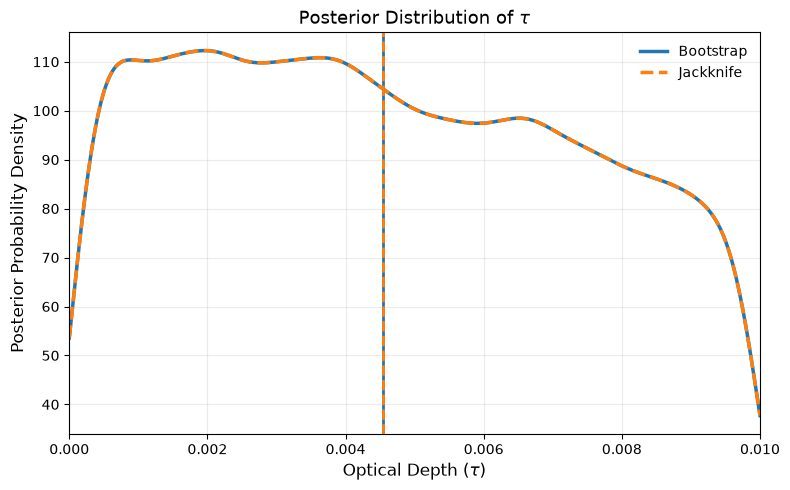


BOOTSTRAP POSTERIOR
tau median        = 4.536048e-03
16th percentile   = 1.458991e-03
84th percentile   = 8.047660e-03
Lower uncertainty = 3.077057e-03
Upper uncertainty = 3.511612e-03

JACKKNIFE POSTERIOR
tau median        = 4.536048e-03
16th percentile   = 1.458991e-03
84th percentile   = 8.047660e-03
Lower uncertainty = 3.077057e-03
Upper uncertainty = 3.511612e-03

POSTERIOR COMPARISON
Difference between medians = 0.000000e+00

Saved: tau_posterior_publication.png

STEP 7 COMPLETE.


In [9]:

#######################################################################
# STEP 7 — COMPARE BOOTSTRAP AND JACKKNIFE TAU POSTERIORS
#######################################################################

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

print("=" * 70)
print("STEP 7: TAU POSTERIOR COMPARISON")
print("=" * 70)


# =========================================================
# LOAD MCMC POSTERIORS
# =========================================================

boot_file = "tau_fit_results_bootstrap.npz"
jk_file = "tau_fit_results_jackknife.npz"

if not os.path.exists(boot_file):
    raise FileNotFoundError(
        f"Missing file: {boot_file}. Run Step 6 first."
    )

if not os.path.exists(jk_file):
    raise FileNotFoundError(
        f"Missing file: {jk_file}. Run Step 5 first."
    )

boot = np.load(boot_file)
jk = np.load(jk_file)

tau_boot = np.asarray(
    boot["samples"],
    dtype=float
)

tau_jk = np.asarray(
    jk["samples"],
    dtype=float
)


# =========================================================
# CHECK POSTERIOR SAMPLES
# =========================================================

tau_boot = tau_boot[np.isfinite(tau_boot)]
tau_jk = tau_jk[np.isfinite(tau_jk)]

if len(tau_boot) == 0 or len(tau_jk) == 0:
    raise ValueError(
        "One or both posterior sample arrays are empty."
    )

tau_min = 0.006
tau_max = 0.04

if (
    np.any(tau_boot < tau_min)
    or np.any(tau_boot > tau_max)
    or np.any(tau_jk < tau_min)
    or np.any(tau_jk > tau_max)
):
    raise ValueError(
        "Posterior samples fall outside the specified tau prior."
    )


# =========================================================
# SUMMARY STATISTICS
# =========================================================

boot_med = np.percentile(tau_boot, 50)
boot_lo = np.percentile(tau_boot, 16)
boot_hi = np.percentile(tau_boot, 84)

jk_med = np.percentile(tau_jk, 50)
jk_lo = np.percentile(tau_jk, 16)
jk_hi = np.percentile(tau_jk, 84)


# =========================================================
# KDE GRID
# =========================================================

x = np.linspace(
    tau_min,
    tau_max,
    2000
)


# =========================================================
# KDE
# =========================================================

if np.std(tau_boot) == 0 or np.std(tau_jk) == 0:
    raise ValueError(
        "KDE cannot be calculated because a posterior "
        "has zero standard deviation."
    )

kde_boot = gaussian_kde(tau_boot)
kde_jk = gaussian_kde(tau_jk)

y_boot = kde_boot(x)
y_jk = kde_jk(x)


# =========================================================
# PLOT
# =========================================================

plt.figure(figsize=(8, 5))


# Bootstrap posterior

plt.plot(
    x,
    y_boot,
    lw=2.5,
    color="tab:blue",
    label="Bootstrap"
)


# Jackknife posterior

plt.plot(
    x,
    y_jk,
    "--",
    lw=2.5,
    color="tab:orange",
    label="Jackknife"
)


# =========================================================
# POSTERIOR MEDIANS
# =========================================================

plt.axvline(
    boot_med,
    color="tab:blue",
    lw=2
)

plt.axvline(
    jk_med,
    color="tab:orange",
    lw=2,
    linestyle="--"
)


# =========================================================
# LABELS
# =========================================================

plt.xlabel(
    r"Optical Depth ($\tau$)",
    fontsize=12
)

plt.ylabel(
    "Posterior Probability Density",
    fontsize=12
)

plt.title(
    r"Posterior Distribution of $\tau$",
    fontsize=13
)

plt.xlim(
    tau_min,
    tau_max
)

plt.grid(alpha=0.25)

plt.legend(frameon=False)

plt.tight_layout()


# =========================================================
# SAVE FIGURE
# =========================================================

plt.savefig(
    "tau_posterior_publication.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =========================================================
# PRINT RESULTS
# =========================================================

print("\n" + "=" * 70)
print("BOOTSTRAP POSTERIOR")
print("=" * 70)

print(f"tau median        = {boot_med:.6e}")
print(f"16th percentile   = {boot_lo:.6e}")
print(f"84th percentile   = {boot_hi:.6e}")
print(f"Lower uncertainty = {boot_med - boot_lo:.6e}")
print(f"Upper uncertainty = {boot_hi - boot_med:.6e}")


print("\n" + "=" * 70)
print("JACKKNIFE POSTERIOR")
print("=" * 70)

print(f"tau median        = {jk_med:.6e}")
print(f"16th percentile   = {jk_lo:.6e}")
print(f"84th percentile   = {jk_hi:.6e}")
print(f"Lower uncertainty = {jk_med - jk_lo:.6e}")
print(f"Upper uncertainty = {jk_hi - jk_med:.6e}")


print("\n" + "=" * 70)
print("POSTERIOR COMPARISON")
print("=" * 70)

print(
    f"Difference between medians = "
    f"{abs(boot_med - jk_med):.6e}"
)

print("\nSaved: tau_posterior_publication.png")

print("\nSTEP 7 COMPLETE.")
print("=" * 70)


In [10]:

#######################################################################
# STEP 8 — TAU SIGNAL-TO-NOISE
#
# S/N = tau / symmetrised uncertainty
#######################################################################

import numpy as np

print("=" * 70)
print("STEP 8: TAU SIGNAL-TO-NOISE")
print("=" * 70)


# ============================================================
# LOAD JACKKNIFE POSTERIOR
# ============================================================

jk = np.load("tau_fit_results_jackknife.npz")

tau_jk_samples = np.asarray(
    jk["samples"],
    dtype=float
)

tau_jk_samples = tau_jk_samples[
    np.isfinite(tau_jk_samples)
]

if len(tau_jk_samples) == 0:
    raise ValueError("No valid jackknife posterior samples found")


# ============================================================
# JACKKNIFE SUMMARY
# ============================================================

tau = float(np.percentile(tau_jk_samples, 50))

tau_lo, tau_hi = np.percentile(
    tau_jk_samples,
    [16, 84]
)

tau_err_plus = float(tau_hi - tau)
tau_err_minus = float(tau - tau_lo)

tau_err_sym = 0.5 * (
    tau_err_plus + tau_err_minus
)

sn = tau / tau_err_sym


# ============================================================
# JACKKNIFE OUTPUT
# ============================================================

print("\nJACKKNIFE MCMC RESULT")

print(f"Tau                     = {tau:.10e}")
print(f"Upper uncertainty       = {tau_err_plus:.10e}")
print(f"Lower uncertainty       = {tau_err_minus:.10e}")
print(f"Symmetrised uncertainty = {tau_err_sym:.10e}")
print(f"S/N                     = {sn:.4f}")
print(f"S/N (rounded)           = {sn:.2f}")


# ============================================================
# LOAD BOOTSTRAP POSTERIOR
# ============================================================

boot = np.load("tau_fit_results_bootstrap.npz")

tau_boot_samples = np.asarray(
    boot["samples"],
    dtype=float
)

tau_boot_samples = tau_boot_samples[
    np.isfinite(tau_boot_samples)
]

if len(tau_boot_samples) == 0:
    raise ValueError("No valid bootstrap posterior samples found")


# ============================================================
# BOOTSTRAP SUMMARY
# ============================================================

tau_boot = float(
    np.percentile(tau_boot_samples, 50)
)

tau_boot_lo, tau_boot_hi = np.percentile(
    tau_boot_samples,
    [16, 84]
)

tau_boot_err_plus = float(
    tau_boot_hi - tau_boot
)

tau_boot_err_minus = float(
    tau_boot - tau_boot_lo
)

tau_boot_err_sym = 0.5 * (
    tau_boot_err_plus + tau_boot_err_minus
)

sn_boot = tau_boot / tau_boot_err_sym


# ============================================================
# BOOTSTRAP OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("BOOTSTRAP TAU RESULT")
print("=" * 70)

print(f"Tau                     = {tau_boot:.10e}")
print(f"Upper uncertainty       = {tau_boot_err_plus:.10e}")
print(f"Lower uncertainty       = {tau_boot_err_minus:.10e}")
print(f"Symmetrised uncertainty = {tau_boot_err_sym:.10e}")
print(f"S/N                     = {sn_boot:.4f}")
print(f"S/N (rounded)           = {sn_boot:.2f}")


# ============================================================
# COMPARISON
# ============================================================

print("\n" + "=" * 70)
print("TAU SIGNAL-TO-NOISE COMPARISON")
print("=" * 70)

print(f"Jackknife S/N = {sn:.4f}")
print(f"Bootstrap S/N = {sn_boot:.4f}")

print(
    f"Difference    = {abs(sn - sn_boot):.4f}"
)

print("=" * 70)
print("STEP 8 COMPLETE.")


STEP 8: TAU SIGNAL-TO-NOISE

JACKKNIFE MCMC RESULT
Tau                     = 4.5360483750e-03
Upper uncertainty       = 3.5116120874e-03
Lower uncertainty       = 3.0770573268e-03
Symmetrised uncertainty = 3.2943347071e-03
S/N                     = 1.3769
S/N (rounded)           = 1.38

BOOTSTRAP TAU RESULT
Tau                     = 4.5360483750e-03
Upper uncertainty       = 3.5116120874e-03
Lower uncertainty       = 3.0770573268e-03
Symmetrised uncertainty = 3.2943347071e-03
S/N                     = 1.3769
S/N (rounded)           = 1.38

TAU SIGNAL-TO-NOISE COMPARISON
Jackknife S/N = 1.3769
Bootstrap S/N = 1.3769
Difference    = 0.0000
STEP 8 COMPLETE.


In [16]:

import numpy as np

for filename in [
    "bootstrap_cluster_results.npz",
    "jackknife_cluster_results.npz"
]:

    print("\n" + "=" * 65)
    print(filename)
    print("=" * 65)

    data = np.load(filename)

    for key in data.files:

        arr = np.asarray(data[key])

        print(
            f"{key:30s} "
            f"shape = {arr.shape}"
        )



bootstrap_cluster_results.npz
bin_edges                      shape = (6,)
r_centers                      shape = (5,)
p_fid                          shape = (5,)
bootstrap                      shape = (1000, 5)
covariance                     shape = (5, 5)
correlation                    shape = (5, 5)
sigma                          shape = (5,)
pair_counts                    shape = (5,)
n_boot                         shape = ()

jackknife_cluster_results.npz
bin_edges                      shape = (6,)
r_centers                      shape = (5,)
p_fid                          shape = (5,)
jackknife                      shape = (50, 5)
jackknife_mean                 shape = (5,)
covariance                     shape = (5, 5)
correlation                    shape = (5, 5)
sigma                          shape = (5,)
pair_counts                    shape = (5,)
n_jack                         shape = ()


CORRELATION MATRICES

Bootstrap correlation matrix:
[[ 1.    -0.007 -0.004 -0.01   0.013]
 [-0.007  1.    -0.001  0.048 -0.032]
 [-0.004 -0.001  1.     0.079  0.025]
 [-0.01   0.048  0.079  1.     0.102]
 [ 0.013 -0.032  0.025  0.102  1.   ]]

Jackknife correlation matrix:
[[ 1.    -0.289  0.048  0.093  0.074]
 [-0.289  1.     0.168  0.215  0.237]
 [ 0.048  0.168  1.     0.113  0.08 ]
 [ 0.093  0.215  0.113  1.     0.1  ]
 [ 0.074  0.237  0.08   0.1    1.   ]]


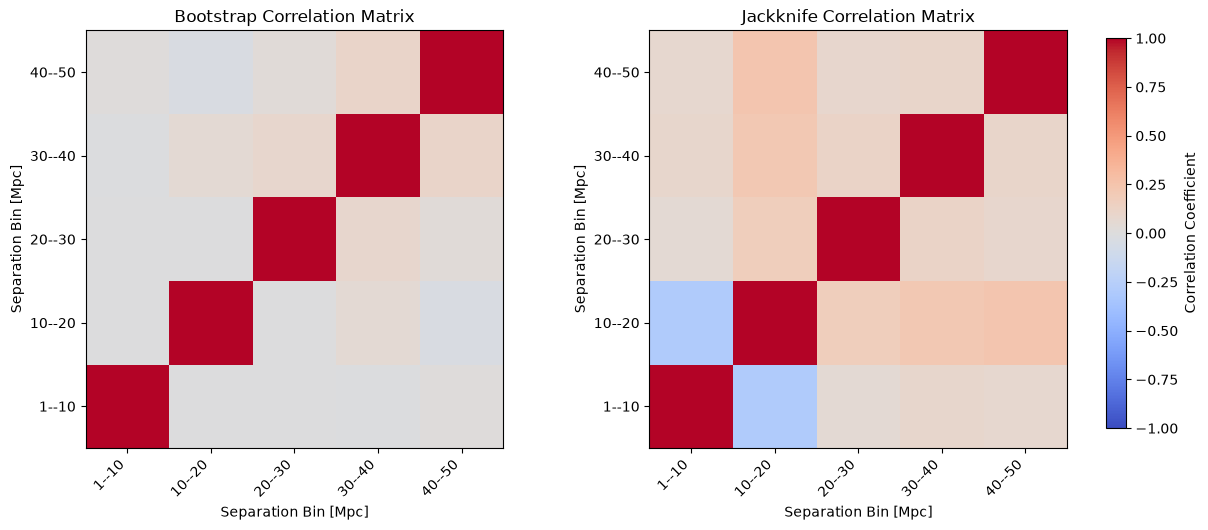


CORRELATION MATRIX ANALYSIS COMPLETE
Saved: bootstrap_jackknife_correlation_matrices.png
Saved: correlation_matrices_d56.npz


In [17]:

#######################################################################
# DESI D56 kSZ — BOOTSTRAP AND JACKKNIFE CORRELATION MATRICES
# FIVE SEPARATION BINS
# SIDE-BY-SIDE PLOT
#######################################################################

import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("CORRELATION MATRICES")
print("=" * 70)


# =====================================================
# LOAD MATRICES
# =====================================================

boot = np.load(
    "bootstrap_cluster_results.npz"
)

jack = np.load(
    "jackknife_cluster_results.npz"
)

boot_cov = np.asarray(
    boot["covariance"],
    dtype=float
)

jack_cov = np.asarray(
    jack["covariance"],
    dtype=float
)


# =====================================================
# CHECK COVARIANCE MATRICES
# =====================================================

if boot_cov.shape != (5, 5):

    raise ValueError(
        f"Bootstrap covariance has shape "
        f"{boot_cov.shape}, expected (5, 5)."
    )

if jack_cov.shape != (5, 5):

    raise ValueError(
        f"Jackknife covariance has shape "
        f"{jack_cov.shape}, expected (5, 5)."
    )


# =====================================================
# SEPARATION BINS
# =====================================================

bin_edges = np.array([
    1, 10, 20, 30, 40, 50
])

bin_labels = [
    "1--10",
    "10--20",
    "20--30",
    "30--40",
    "40--50"
]

bin_centers = 0.5 * (
    bin_edges[:-1] + bin_edges[1:]
)


# =====================================================
# CONVERT COVARIANCE TO CORRELATION
# =====================================================

def cov_to_corr(cov):

    sigma = np.sqrt(
        np.diag(cov)
    )

    if np.any(~np.isfinite(sigma)):

        raise ValueError(
            "Covariance matrix contains "
            "non-finite diagonal values."
        )

    if np.any(sigma <= 0):

        raise ValueError(
            "Covariance matrix contains "
            "zero or negative diagonal values."
        )

    corr = cov / np.outer(
        sigma,
        sigma
    )

    return corr


# =====================================================
# CALCULATE CORRELATION MATRICES
# =====================================================

boot_corr = cov_to_corr(
    boot_cov
)

jack_corr = cov_to_corr(
    jack_cov
)


# =====================================================
# FORCE NUMERICAL SYMMETRY
# =====================================================

boot_corr = 0.5 * (
    boot_corr + boot_corr.T
)

jack_corr = 0.5 * (
    jack_corr + jack_corr.T
)


# =====================================================
# PRINT MATRICES
# =====================================================

print("\nBootstrap correlation matrix:")

print(
    np.array2string(
        boot_corr,
        precision=3,
        suppress_small=True
    )
)

print("\nJackknife correlation matrix:")

print(
    np.array2string(
        jack_corr,
        precision=3,
        suppress_small=True
    )
)


# =====================================================
# SIDE-BY-SIDE CORRELATION MATRICES
# =====================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 6)
)


# =====================================================
# BOOTSTRAP CORRELATION MATRIX
# =====================================================

im = axes[0].imshow(
    boot_corr,
    origin="lower",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

axes[0].set_title(
    "Bootstrap Correlation Matrix"
)

axes[0].set_xticks(
    np.arange(5)
)

axes[0].set_xticklabels(
    bin_labels,
    rotation=45,
    ha="right"
)

axes[0].set_yticks(
    np.arange(5)
)

axes[0].set_yticklabels(
    bin_labels
)

axes[0].set_xlabel(
    "Separation Bin [Mpc]"
)

axes[0].set_ylabel(
    "Separation Bin [Mpc]"
)


# =====================================================
# JACKKNIFE CORRELATION MATRIX
# =====================================================

axes[1].imshow(
    jack_corr,
    origin="lower",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

axes[1].set_title(
    "Jackknife Correlation Matrix"
)

axes[1].set_xticks(
    np.arange(5)
)

axes[1].set_xticklabels(
    bin_labels,
    rotation=45,
    ha="right"
)

axes[1].set_yticks(
    np.arange(5)
)

axes[1].set_yticklabels(
    bin_labels
)

axes[1].set_xlabel(
    "Separation Bin [Mpc]"
)

axes[1].set_ylabel(
    "Separation Bin [Mpc]"
)


# =====================================================
# SHARED COLOUR BAR ON THE FAR RIGHT
# =====================================================

fig.subplots_adjust(
    right=0.88,
    wspace=0.35
)

cbar_ax = fig.add_axes(
    [0.91, 0.18, 0.015, 0.65]
)

fig.colorbar(
    im,
    cax=cbar_ax,
    label="Correlation Coefficient"
)


# =====================================================
# SAVE FIGURE
# =====================================================

plt.savefig(
    "bootstrap_jackknife_correlation_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =====================================================
# SAVE CORRELATION MATRICES
# =====================================================

np.savez(
    "correlation_matrices_d56.npz",
    bootstrap_correlation=boot_corr,
    jackknife_correlation=jack_corr,
    bin_edges=bin_edges,
    bin_centers=bin_centers
)


# =====================================================
# COMPLETE
# =====================================================

print("\n" + "=" * 70)
print("CORRELATION MATRIX ANALYSIS COMPLETE")
print("=" * 70)

print(
    "Saved: bootstrap_jackknife_correlation_matrices.png"
)

print(
    "Saved: correlation_matrices_d56.npz"
)

print("=" * 70)


DESI D56 FOOTPRINT
Number of objects: 45711
RA range: 0.0080 to 359.9917 degrees
Dec range: -6.7997 to 3.4936 degrees


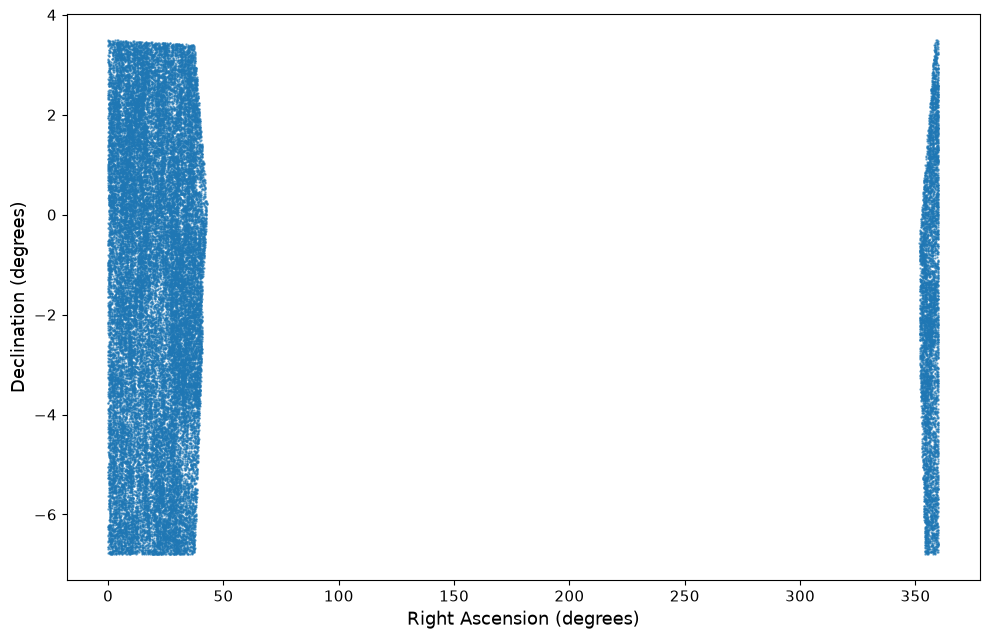


Figure saved as d56_footprint.png


In [4]:

import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# LOAD DESI D56 COORDINATES
# =========================================================

coords = np.loadtxt(
    "desi_d56.dat",
    usecols=(0, 1)
)

ra_deg = coords[:, 0]
dec_deg = coords[:, 1]

# =========================================================
# DISPLAY DATA INFORMATION
# =========================================================

print("=" * 60)
print("DESI D56 FOOTPRINT")
print("=" * 60)

print(f"Number of objects: {len(ra_deg)}")
print(f"RA range: {ra_deg.min():.4f} to {ra_deg.max():.4f} degrees")
print(f"Dec range: {dec_deg.min():.4f} to {dec_deg.max():.4f} degrees")

# =========================================================
# PLOT THE FOOTPRINT
# =========================================================

fig, ax = plt.subplots(figsize=(10, 6.5))

ax.scatter(
    ra_deg,
    dec_deg,
    s=0.5,
    alpha=0.6,
    rasterized=True
)

ax.set_xlabel("Right Ascension (degrees)", fontsize=13)
ax.set_ylabel("Declination (degrees)", fontsize=13)

#ax.set_title(
#    "Spatial Distribution of DESI D56 Objects",
#    fontsize=14
#)

#ax.grid(
#    True,
#    linestyle="--",
#    linewidth=0.5,
#    alpha=0.5
#)

ax.tick_params(axis="both", labelsize=11)

plt.tight_layout()

# =========================================================
# SAVE HIGH-RESOLUTION FIGURE
# =========================================================

plt.savefig(
    "d56_footprint.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure saved as d56_footprint.png")
print("=" * 60)

Number of DESI objects: 45711


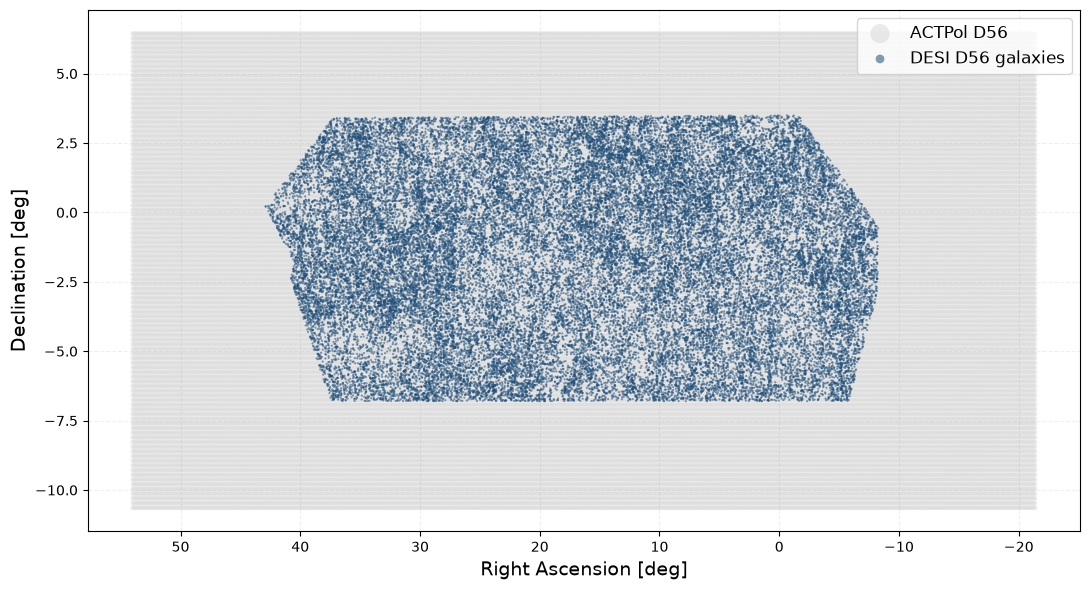

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS

# ==========================================
# 1. LOAD DESI D56 COORDINATES
# ==========================================

coords = np.loadtxt("desi_d56.dat", usecols=(0, 1))

ra_desi  = coords[:, 0]
dec_desi = coords[:, 1]

print("Number of DESI objects:", len(ra_desi))


# ==========================================
# 2. LOAD ACTPOL D56 MAP
# ==========================================

act_file = "ACTPol_148_D56_PA2_S2_1way_I_src_free.fits"

with fits.open(act_file) as hdul:
    act_map = hdul[0].data
    header = hdul[0].header

act_map = np.squeeze(act_map)

wcs = WCS(header).celestial


# ==========================================
# 3. FIND ACTPOL SKY COORDINATES
# ==========================================

ny, nx = act_map.shape

# Use a coarse grid so plotting is fast
step = 20

y, x = np.mgrid[0:ny:step, 0:nx:step]

ra_act, dec_act = wcs.pixel_to_world_values(x, y)

ra_act = np.asarray(ra_act)
dec_act = np.asarray(dec_act)


# ==========================================
# 4. HANDLE RA = 0 / 360 DEGREE WRAP
# ==========================================

# Convert RA > 180 deg to negative RA
# e.g. 355 deg becomes -5 deg

ra_desi_plot = np.where(ra_desi > 180,
                        ra_desi - 360,
                        ra_desi)

ra_act_plot = np.where(ra_act > 180,
                       ra_act - 360,
                       ra_act)


# ==========================================
# 5. VALID ACTPOL PIXELS
# ==========================================

sampled_map = act_map[::step, ::step]

valid = (
    np.isfinite(sampled_map) &
    np.isfinite(ra_act_plot) &
    np.isfinite(dec_act)
)


# ==========================================
# 6. PLOT OVERLAP
# ==========================================

plt.figure(figsize=(11, 6))

# ACTPol D56 footprint
plt.scatter(
    ra_act_plot[valid],
    dec_act[valid],
    s=12,
    color="#D9D9D9",       # soft light grey
    alpha=0.55,
    edgecolors="none",
    label="ACTPol D56"
)

# DESI D56 galaxies
plt.scatter(
    ra_desi_plot,
    dec_desi,
    s=2.5,
    color="#1F4E79",       # deep blue
    alpha=0.55,
    edgecolors="none",
    label="DESI D56 galaxies"
)

plt.xlabel("Right Ascension [deg]", fontsize=14)
plt.ylabel("Declination [deg]", fontsize=14)

#plt.title(
 #   "DESI D56 and ACTPol D56 Sky Footprint",
#    fontsize=16
#)

plt.legend(
    fontsize=12,
    markerscale=4,
    frameon=True
)

plt.grid(
    alpha=0.20,
    linestyle="--"
)

# Astronomical convention
plt.gca().invert_xaxis()

plt.tight_layout()

plt.savefig(
    "DESI_ACTPol_D56_overlap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
